# Robustez · Fase 3

Comprueba si los resultados de la fase 3 (`09_fase3_trafico`: **tráfico y canasta**) se mantienen cuando se cambia una decisión del análisis por otra razonable. El modelo principal reproduce `09_fase3_trafico` tal como está; cada prueba cambia **una sola cosa** y vuelve a estimar las 21 ecuaciones (1 de tráfico, 10 de total y 10 de canasta) con una matriz de diseño común, de modo que la identidad *total = tráfico + canasta* se sigue cumpliendo en cada prueba (se verifica).

**Qué pruebas se hacen y de dónde salen** (lista de robustez de `metodologia.md` §4 y decisiones D‑09, D‑15, D‑16, D‑24, D‑29; no se inventa ninguna):

| Código | Prueba | Qué se cambia | Por qué (decisión) | Tipo |
|---|---|---|---|---|
| `principal` | Modelo principal | Nada: reproduce `09_fase3_trafico` | — | Referencia |
| `hac_14` | Newey‑West con 14 rezagos | 14 rezagos en vez de 7 en los errores estándar | D‑15: "7 a 14 rezagos"; el principal usa el extremo inferior | Parámetro |
| `efectos_fijos_semana` | Efectos fijos de semana | Año‑mes → semana | D‑16, opción (b2) | Especificación |
| `sin_diciembre` | Sin diciembre | Se excluye diciembre de 2016 | `metodologia.md` §4.1 | Corte de tiempo |
| `terremoto_corto` | Ventana corta del terremoto | Se excluye solo hasta el 16‑05‑2016 | D‑09 | Corte de tiempo |
| `intensidad_log` | Intensidad en logaritmo | $\log(1+N_{kt})$ en vez de proporción | D‑07, `metodologia.md` §4.3 | Medición |
| `skus_todo_el_periodo` | SKUs presentes todo el período | Las ventas agregadas $Y_{jt}$ suman solo los SKUs presentes los 590 días | D‑24 | Submuestra |
| `placebo_adelanto` | Placebo con adelantos | Se agrega la intensidad de cada categoría en los **3 días siguientes** | `metodologia.md` §4.7 | Falsificación |
| — | Corrección al 10 % | Benjamini‑Hochberg al 10 % (sin reestimar) | D‑15 | Parámetro |

**Ya hecha en otro notebook:** la comparación entre la fase 2 (PPML, panel SKU) y el efecto total de la fase 3 (MCO, agregado), `metodologia.md` §4.5, está en `09_fase3_trafico`, Paso 10.

**Qué no se hace y por qué** (limitación): cotas de la imputación de promociones (D‑25) y otra tienda, porque exigen rehacer la preparación de datos.

| | |
|---|---|
| **Entrada** | `panel_t44_sku_dia.parquet`, `calendario_t44.csv`, `exposicion_t44_categorias_dia.csv` (los mismos de `09_fase3_trafico`) e `intensidad_t44_categoria_dia.csv` (para $\log(1+N)$); `fase3_coeficientes.csv` solo para verificar, si existe |
| **Tablas** (en `resultados/tablas/`) | `robustez_fase3_coeficientes.csv`, `robustez_fase3_consistencia.csv`, `robustez_fase3_resumen.csv`, `robustez_fase3_cambios.csv`, `robustez_fase3_placebo.csv`, `robustez_fase3_bh10.csv`, `robustez_fase3_muestras.csv` |
| **Figura** | `robustez_fase3_trafico.png` |
| **No modifica** | ningún notebook ni archivo existente: todas las salidas empiezan con `robustez_fase3_` |

Son regresiones diarias por mínimos cuadrados: el notebook completo tarda **pocos minutos**.

## Guía rápida: qué se busca en la fase 3

La fase 3 responde si una categoría en promoción **atrae clientes** a la tienda ($\phi_k$, efecto sobre las boletas diarias) y descompone el efecto sobre las ventas de otra categoría en **tráfico** (más visitas) y **canasta** (más venta por visita). En el principal, ninguna categoría funcionó como gancho de tráfico; DELI apareció asociada a **menos** tráfico, y 4 pares cruzados tuvieron efecto total significativo (todos con DELI en promoción).

La robustez pregunta: **¿esas conclusiones se mantienen?**

| Columna | Lectura |
|---|---|
| `mismo_signo` | El efecto apunta en la misma dirección que en el principal. |
| `misma_conclusion` | La misma clasificación (por ejemplo, "reduce tráfico" o "sin efecto"). |
| `diferencia_pp` | Cuánto cambia el efecto de +10 pp, en puntos porcentuales (no se calcula para `intensidad_log`, que mide en otra escala). |
| `dentro_ic_principal` | El nuevo valor cae dentro del intervalo del principal. |

**Lectura especial de `hac_14`:** solo cambia los errores estándar, nunca los coeficientes. Si una conclusión cambia ahí, depende de cuánta autocorrelación se supone entre días.

**El placebo** usa la promoción **futura**: si la intensidad de mañana "explica" el tráfico de hoy, hay confusión temporal o promociones anunciadas.

## Paso 1. Librerías y parámetros

Los parámetros del modelo son **copias exactas** de `09_fase3_trafico`.

In [1]:
# ------------------------------------------------------------------------------------------------------------
# Este notebook aplica las pruebas de robustez de la metodología (metodologia.md §4, D-29) a la fase 3
# (09_fase3_trafico): Newey-West con 14 rezagos, efectos fijos de semana, sin diciembre, ventana corta del
# terremoto, intensidad en logaritmo, SKUs presentes todo el período, placebo con adelantos y BH al 10 %.
# ------------------------------------------------------------------------------------------------------------
# Implementación: NachaJavi (con asistencia de Claude), a partir de 09_fase3_trafico
# Fecha de versión: 2026-11-11
# ------------------------------------------------------------------------------------------------------------

# Librerías
# ------------------------------------------------------------------------------------------------------------
import os
import re

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

# Parámetros del modelo (copiados de 09_fase3_trafico)
# ------------------------------------------------------------------------------------------------------------
categorias = [
    "BEVERAGES", "GROCERY I", "CLEANING", "DAIRY", "BREAD/BAKERY", "LIQUOR,WINE,BEER",
    "MEATS", "POULTRY", "DELI", "PRODUCE",
]
categorias_programa = ["MEATS", "POULTRY", "DELI", "PRODUCE"]   # D-26
controles_calendario = [
    "dia_libre", "adicional", "dia_laboral_recuperado", "evento_comercial", "evento_otro", "dia_pago", "post_pago",
]
variable_trafico = "transactions"   # D-12
variable_ventas = "unit_sales"      # D-20: ventas netas en los agregados
efectos_fijos = ["dow", "mes"]      # D-16
rezagos_hac = 7                     # D-15
delta_p = 0.10
alfa = 0.05
columna_categoria = {c: "p__" + re.sub(r"[^A-Z0-9]+", "_", c).strip("_") for c in categorias}
regresores_intensidad = [columna_categoria[c] for c in categorias]

# Parámetros de las pruebas de robustez
# ------------------------------------------------------------------------------------------------------------
especificaciones = {
    "principal":            "Modelo principal (09_fase3_trafico)",
    "hac_14":               "Newey-West con 14 rezagos (D-15)",
    "efectos_fijos_semana": "Efectos fijos de semana en vez de año-mes (D-16)",
    "sin_diciembre":        "Sin diciembre de 2016",
    "terremoto_corto":      "Ventana del terremoto hasta el 16-05-2016 (D-09)",
    "intensidad_log":       "Intensidad como log(1+N) (D-07)",
    "skus_todo_el_periodo": "Ventas agregadas solo de SKUs presentes los 590 días (D-24)",
    "placebo_adelanto":     "Placebo: intensidad de los 3 días siguientes",
}
rezagos_hac_alternativo = 14                       # D-15: extremo superior
efectos_fijos_semana = ["dow", "semana"]           # D-16, opción (b2)
mes_excluido = 12
alfa_alternativo = 0.10
regresores_adelanto = [f"{c}_f1_3" for c in regresores_intensidad]

# Rutas
# ------------------------------------------------------------------------------------------------------------
ruta_procesados = os.path.join("..", "data", "procesados")
ruta_tablas = os.path.join("resultados", "tablas")
ruta_figuras = os.path.join("resultados", "figuras")
os.makedirs(ruta_tablas, exist_ok=True)
os.makedirs(ruta_figuras, exist_ok=True)
prefijo = "robustez_fase3"
archivo_principal_09 = os.path.join(ruta_tablas, "fase3_coeficientes.csv")   # solo para verificar

## Paso 2. Importar los datos y armar las variables de cada prueba

Igual que `09_fase3_trafico`, más dos cosas que necesitan las pruebas:

- **Ventas agregadas de los SKUs presentes todo el período** (para `skus_todo_el_periodo`).
- **$\log(1+N_{kt})$**, con $N_{kt}$ el número de SKUs de $k$ en promoción **fuera del programa**, desde `intensidad_t44_categoria_dia.csv` (para `intensidad_log`).

Las intensidades de la fase 3 son del **mismo día** (sin rezagos), así que la ventana corta del terremoto no exige recalcular nada: solo vuelven a la muestra los días del 17 al 31 de mayo.

In [2]:
panel = pd.read_parquet(os.path.join(ruta_procesados, "panel_t44_sku_dia.parquet"), columns=["date", "item_nbr", "family", variable_ventas])
calendario = pd.read_csv(os.path.join(ruta_procesados, "calendario_t44.csv"), parse_dates=["date"])
exposicion_categorias = pd.read_csv(os.path.join(ruta_procesados, "exposicion_t44_categorias_dia.csv"), parse_dates=["date"])
intensidad = pd.read_csv(os.path.join(ruta_procesados, "intensidad_t44_categoria_dia.csv"), parse_dates=["date"])
intensidad["family"] = intensidad["family"].astype(str)
panel["family"] = panel["family"].astype(str)

assert len(calendario) == len(exposicion_categorias) == 590, "las tablas diarias no tienen 590 días"
assert set(regresores_intensidad + regresores_adelanto) <= set(exposicion_categorias.columns), "faltan columnas de intensidad"
assert not calendario["date"].duplicated().any(), "hay fechas repetidas en el calendario"
assert (calendario["date"].to_numpy() == exposicion_categorias["date"].to_numpy()).all(), "las fechas diarias no están alineadas"


def ventas_por_dia(datos: pd.DataFrame) -> pd.DataFrame:
    """
    Esta función suma las ventas netas de cada categoría del núcleo por día (igual que el Paso 3 de 09_fase3_trafico).

    :param datos:   un DataFrame SKU-día con las columnas date, family y unit_sales.
    :return:        un DataFrame con una fila por día y una columna por categoría.
    """
    ventas = (datos.loc[datos["family"].isin(categorias)].groupby(["family", "date"], observed=True)[variable_ventas]
              .sum().unstack("family").reindex(columns=categorias))
    return ventas.reindex(calendario["date"]).fillna(0.0)


# Ventas agregadas: todas (principal) y solo los SKUs presentes los 590 días (D-24)
dias_por_sku = panel.groupby("item_nbr").size()
skus_completos = set(dias_por_sku.index[dias_por_sku == len(calendario)])
ventas_todas = ventas_por_dia(panel)
ventas_completos = ventas_por_dia(panel.loc[panel["item_nbr"].isin(skus_completos)])
assert ventas_todas.notna().all().all() and (ventas_todas.index == calendario["date"]).all(), "faltan días en las ventas"

# Intensidad como log(1 + N fuera del programa) (D-07), en formato ancho con los mismos nombres de columna
log_n = (intensidad.pivot(index="date", columns="family", values="n_promo_fuera_programa")
         .reindex(calendario["date"]).fillna(0.0)[categorias])
log_n = np.log1p(log_n)
log_n.columns = [columna_categoria[c] for c in log_n.columns]

# Verificar que la proporción de 03_exposiciones coincide con la de intensidad_t44 (misma fuente)
prop = (intensidad.pivot(index="date", columns="family", values="p_prop_fuera_programa")
        .reindex(calendario["date"]).fillna(0.0)[categorias])
prop.columns = [columna_categoria[c] for c in prop.columns]
diferencia = (prop.reset_index(drop=True) - exposicion_categorias[regresores_intensidad]).abs().max().max()
assert diferencia < 1e-5, f"las intensidades de las dos fuentes no coinciden ({diferencia})"

print(f"calendario: {len(calendario)} días | SKUs presentes los 590 días: {len(skus_completos):,} de {panel['item_nbr'].nunique():,}")
print(f"ventana del terremoto: larga = {int(calendario['ventana_terremoto'].sum())} días, corta (eventos del terremoto) = "
      f"{int(calendario['terremoto'].astype(bool).sum())} días | días de diciembre: {(calendario['date'].dt.month == mes_excluido).sum()}")
print(f"Participación de los SKUs completos en las ventas de cada categoría (%):")
print((100 * ventas_completos.sum() / ventas_todas.sum()).round(1).to_string())

calendario: 590 días | SKUs presentes los 590 días: 2,122 de 3,656
ventana del terremoto: larga = 46 días, corta (eventos del terremoto) = 31 días | días de diciembre: 30
Participación de los SKUs completos en las ventas de cada categoría (%):
family
BEVERAGES           67.199997
GROCERY I           82.099998
CLEANING            83.099998
DAIRY               74.300003
BREAD/BAKERY        78.500000
LIQUOR,WINE,BEER    63.299999
MEATS               97.199997
POULTRY             92.199997
DELI                91.500000
PRODUCE             92.800003


**Cómo leer esta salida.** La última tabla dice qué parte de las ventas de cada categoría viene de los SKUs presentes todo el período. Si es alta, la prueba `skus_todo_el_periodo` cambia poco la variable dependiente; si es baja, cambia mucho y es esperable que los efectos se muevan más.

## Paso 3. Muestra, matriz de diseño y estimación de cada prueba

`muestra_de` arma los días de cada prueba con las exclusiones de `09_fase3_trafico` (ventana del terremoto y días sin transacciones) más el cambio de la prueba. `construir_matriz_diseno`, `estimar` y `coeficientes_intensidad` son **copias** de `09_fase3_trafico`, con los efectos fijos, los rezagos de Newey‑West y los regresores como argumentos.

Dentro de cada prueba se mantiene la regla de oro de la fase 3: **las 21 ecuaciones usan la misma muestra y la misma matriz de diseño**, y se verifica que *total = tráfico + canasta* coeficiente por coeficiente.

In [3]:
def muestra_de(especificacion: str) -> pd.DataFrame:
    """
    Esta función arma la muestra de días de una prueba: calendario, intensidades y ventas agregadas, con las
    exclusiones de 09_fase3_trafico y el cambio de la prueba.

    :param especificacion:  el código de la prueba.
    :return:                un DataFrame con una fila por día usado.
    """
    intensidades = log_n.reset_index(drop=True) if especificacion == "intensidad_log" else exposicion_categorias[regresores_intensidad]
    ventas = ventas_completos if especificacion == "skus_todo_el_periodo" else ventas_todas
    dias = pd.concat([calendario.reset_index(drop=True), intensidades.reset_index(drop=True),
                      exposicion_categorias[regresores_adelanto].reset_index(drop=True),
                      ventas.reset_index(drop=True)], axis=1)
    assert len(dias) == 590, "una unión cambió el número de días"

    # Exclusiones de 09_fase3_trafico: ventana del terremoto (D-09) y días sin transacciones (D-12)
    ventana = dias["terremoto"].astype(bool) if especificacion == "terremoto_corto" else dias["ventana_terremoto"]
    muestra = dias.loc[~ventana & dias[variable_trafico].notna()]

    # Cambios de muestra de cada prueba
    if especificacion == "sin_diciembre":
        muestra = muestra.loc[muestra["date"].dt.month != mes_excluido]
    if especificacion == "placebo_adelanto":
        muestra = muestra.dropna(subset=regresores_adelanto)
    return muestra.reset_index(drop=True)


def construir_matriz_diseno(muestra: pd.DataFrame, regresores: list, fijos: list) -> pd.DataFrame:
    """
    Esta función arma la matriz de diseño común de las 21 regresiones (copia de 09_fase3_trafico, con los
    regresores y los efectos fijos como argumentos).

    :param muestra:     un DataFrame con una fila por día.
    :param regresores:  las intensidades (y, en el placebo, sus adelantos).
    :param fijos:       las columnas de efectos fijos.
    :return:            un DataFrame de regresores con constante.
    """
    diseno = muestra[regresores + controles_calendario].astype(float)
    ficticias = [pd.get_dummies(muestra[efecto], prefix=efecto, drop_first=True).astype(float) for efecto in fijos]
    diseno = pd.concat([diseno] + ficticias, axis=1)
    constantes = diseno.columns[diseno.nunique() <= 1].tolist()
    if constantes:
        diseno = diseno.drop(columns=constantes)
    return sm.add_constant(diseno)


def estimar(y: np.ndarray, diseno: pd.DataFrame, rezagos: int):
    """
    Esta función estima una ecuación por MCO con errores HAC de Newey-West (copia de 09_fase3_trafico).

    :param y:           la variable dependiente (en logaritmos).
    :param diseno:      la matriz de diseño común.
    :param rezagos:     los rezagos de Newey-West.
    :return:            el resultado de statsmodels.
    """
    return sm.OLS(y, diseno).fit(cov_type="HAC", cov_kwds={"maxlags": rezagos}, use_t=True)


def coeficientes_intensidad(modelo, ecuacion: str, categoria: str, regresores: list) -> pd.DataFrame:
    """
    Esta función extrae los coeficientes de una lista de regresores, con su error estándar, valor p, intervalo de
    95 % y efecto en porcentaje por +10 pp (copia de 09_fase3_trafico, con los regresores como argumento).

    :param modelo:      un modelo estimado con estimar().
    :param ecuacion:    'trafico', 'total' o 'canasta'.
    :param categoria:   la categoría afectada j ('-' en tráfico).
    :param regresores:  los nombres de los coeficientes que se extraen.
    :return:            un DataFrame con una fila por regresor.
    """
    intervalo = modelo.conf_int(alpha=0.05).loc[regresores]
    nombres = {columna_categoria[c]: c for c in categorias}
    tabla = pd.DataFrame({
        "ecuacion": ecuacion, "categoria_afectada_j": categoria,
        "categoria_en_promocion_k": [nombres[r.replace("_f1_3", "")] for r in regresores],
        "es_adelanto": [r.endswith("_f1_3") for r in regresores],
        "beta": modelo.params[regresores].to_numpy(), "ee": modelo.bse[regresores].to_numpy(),
        "p_valor": modelo.pvalues[regresores].to_numpy(),
        "ic_inf": intervalo.iloc[:, 0].to_numpy(), "ic_sup": intervalo.iloc[:, 1].to_numpy(),
    })
    for nombre, columna in [("efecto_pct", "beta"), ("efecto_ic_inf_pct", "ic_inf"), ("efecto_ic_sup_pct", "ic_sup")]:
        tabla[nombre] = 100 * np.expm1(delta_p * tabla[columna])
    return tabla


def estimar_prueba(especificacion: str) -> tuple:
    """
    Esta función estima las 21 ecuaciones de la fase 3 para una prueba y verifica la identidad tráfico + canasta.

    :param especificacion:  el código de la prueba.
    :return:                una tupla (coeficientes, resumen de la muestra).
    """
    muestra = muestra_de(especificacion)
    regresores = regresores_intensidad + (regresores_adelanto if especificacion == "placebo_adelanto" else [])
    fijos = efectos_fijos_semana if especificacion == "efectos_fijos_semana" else efectos_fijos
    rezagos = rezagos_hac_alternativo if especificacion == "hac_14" else rezagos_hac
    diseno = construir_matriz_diseno(muestra, regresores, fijos)
    rango = np.linalg.matrix_rank(diseno.to_numpy())
    assert rango == diseno.shape[1], f"{especificacion}: la matriz de diseño no tiene rango completo"

    log_trafico = np.log(muestra[variable_trafico].to_numpy())
    tablas = [coeficientes_intensidad(estimar(log_trafico, diseno, rezagos), "trafico", "-", regresores)]
    for categoria in categorias:
        log_total = np.log1p(muestra[categoria].to_numpy())
        tablas.append(coeficientes_intensidad(estimar(log_total, diseno, rezagos), "total", categoria, regresores))
        tablas.append(coeficientes_intensidad(estimar(log_total - log_trafico, diseno, rezagos), "canasta", categoria, regresores))
    tabla = pd.concat(tablas, ignore_index=True).assign(especificacion=especificacion)

    # Verificar la identidad total = tráfico + canasta en esta prueba
    b = tabla.pivot_table(index=["categoria_afectada_j", "categoria_en_promocion_k", "es_adelanto"], columns="ecuacion",
                          values="beta").dropna(subset=["total"]).reset_index()
    phi = tabla.loc[tabla["ecuacion"] == "trafico"].set_index(["categoria_en_promocion_k", "es_adelanto"])["beta"]
    b["trafico"] = [phi[(k, a)] for k, a in zip(b["categoria_en_promocion_k"], b["es_adelanto"])]
    residuo = (b["total"] - b["trafico"] - b["canasta"]).abs().max()
    assert residuo < 1e-8, f"{especificacion}: la identidad total = tráfico + canasta no se cumple ({residuo})"

    resumen = {"especificacion": especificacion, "n_dias": len(muestra), "n_regresores": diseno.shape[1],
               "grados_libertad": len(muestra) - diseno.shape[1], "rezagos_hac": rezagos, "residuo_identidad": residuo}
    return tabla, resumen

## Paso 4. Estimar todas las pruebas

In [4]:
tablas, muestras = [], []
for especificacion, descripcion in especificaciones.items():
    tabla, resumen = estimar_prueba(especificacion)
    tablas.append(tabla)
    muestras.append(resumen)
    print(f"{descripcion:62s} días {resumen['n_dias']:>3} | regresores {resumen['n_regresores']:>3} | "
          f"g.l. {resumen['grados_libertad']:>3} | identidad OK (residuo {resumen['residuo_identidad']:.1e})")
coeficientes = pd.concat(tablas, ignore_index=True)
muestras = pd.DataFrame(muestras)

# Benjamini-Hochberg dentro de cada prueba, en las familias de 09_fase3_trafico (más la del placebo)
coeficientes["es_propia"] = coeficientes["categoria_afectada_j"] == coeficientes["categoria_en_promocion_k"]
coeficientes["p_bh"] = np.nan
for especificacion in especificaciones:
    familias = {
        "trafico": (coeficientes["ecuacion"] == "trafico") & ~coeficientes["es_adelanto"],
        "total": (coeficientes["ecuacion"] == "total") & ~coeficientes["es_propia"] & ~coeficientes["es_adelanto"],
        "canasta": (coeficientes["ecuacion"] == "canasta") & ~coeficientes["es_propia"] & ~coeficientes["es_adelanto"],
        "adelanto_trafico": (coeficientes["ecuacion"] == "trafico") & coeficientes["es_adelanto"],
        "adelanto_total": (coeficientes["ecuacion"] == "total") & coeficientes["es_adelanto"],
    }
    for filtro in familias.values():
        filtro = filtro & (coeficientes["especificacion"] == especificacion)
        if filtro.any():
            coeficientes.loc[filtro, "p_bh"] = multipletests(coeficientes.loc[filtro, "p_valor"], alpha=alfa, method="fdr_bh")[1]
coeficientes["p_criterio"] = coeficientes["p_bh"].fillna(coeficientes["p_valor"])
coeficientes["significativo"] = coeficientes["p_criterio"] < alfa
etiquetas_pos = np.where(coeficientes["ecuacion"] == "trafico", "atrae tráfico", "sinergia")
etiquetas_neg = np.where(coeficientes["ecuacion"] == "trafico", "reduce tráfico", "canibalización")
coeficientes["clasificacion"] = np.where(
    coeficientes["significativo"] & (coeficientes["beta"] > 0), etiquetas_pos,
    np.where(coeficientes["significativo"] & (coeficientes["beta"] < 0), etiquetas_neg, "sin efecto"),
)

Modelo principal (09_fase3_trafico)                            días 542 | regresores  42 | g.l. 500 | identidad OK (residuo 2.0e-14)
Newey-West con 14 rezagos (D-15)                               días 542 | regresores  42 | g.l. 500 | identidad OK (residuo 2.0e-14)
Efectos fijos de semana en vez de año-mes (D-16)               días 542 | regresores 103 | g.l. 439 | identidad OK (residuo 4.3e-14)
Sin diciembre de 2016                                          días 512 | regresores  41 | g.l. 471 | identidad OK (residuo 1.2e-14)
Ventana del terremoto hasta el 16-05-2016 (D-09)               días 557 | regresores  43 | g.l. 514 | identidad OK (residuo 1.1e-14)
Intensidad como log(1+N) (D-07)                                días 542 | regresores  42 | g.l. 500 | identidad OK (residuo 5.8e-16)
Ventas agregadas solo de SKUs presentes los 590 días (D-24)    días 542 | regresores  42 | g.l. 500 | identidad OK (residuo 1.2e-14)
Placebo: intensidad de los 3 días siguientes                   días 5

**Cómo leer esta salida.** Una línea por prueba: días usados (el principal debe tener 542, como `09_fase3_trafico`), número de regresores y grados de libertad. "identidad OK" confirma que en esa prueba *total = tráfico + canasta* se cumple exactamente. Con efectos fijos de semana los grados de libertad bajan bastante: es la prueba más exigente.

### Verificación: el modelo principal reproduce `09_fase3_trafico`

In [5]:
if os.path.exists(archivo_principal_09):
    anteriores = pd.read_csv(archivo_principal_09)
    claves = ["ecuacion", "categoria_afectada_j", "categoria_en_promocion_k"]
    comparar = coeficientes.loc[coeficientes["especificacion"] == "principal"].merge(anteriores, on=claves, suffixes=("", "_09"))
    diferencia_maxima = (comparar["beta"] - comparar["beta_09"]).abs().max()
    assert len(comparar) == 210 and diferencia_maxima < 1e-8, f"el principal no reproduce 09_fase3_trafico ({diferencia_maxima})"
    print(f"El principal reproduce 09_fase3_trafico en {len(comparar)} coeficientes (diferencia máxima {diferencia_maxima:.1e}).")
else:
    print(f"No se encontró {archivo_principal_09}: corra 09_fase3_trafico para esta verificación (no es necesaria para seguir).")

El principal reproduce 09_fase3_trafico en 210 coeficientes (diferencia máxima 0.0e+00).


## Paso 5. Consistencia de cada prueba con el principal

Se comparan tres grupos de efectos: el **tráfico** de cada categoría ($\phi_k$, 10), el **efecto total cruzado** (90 pares) y el **efecto canasta cruzado** (90 pares). En `intensidad_log` la escala es otra, así que solo se comparan el signo y la conclusión.

In [6]:
claves = ["ecuacion", "categoria_afectada_j", "categoria_en_promocion_k"]
base = coeficientes.loc[~coeficientes["es_adelanto"] & ((coeficientes["ecuacion"] == "trafico") | ~coeficientes["es_propia"])]
principal = base.loc[base["especificacion"] == "principal"].set_index(claves)
consistencia = base.loc[base["especificacion"] != "principal"].join(
    principal[["efecto_pct", "efecto_ic_inf_pct", "efecto_ic_sup_pct", "clasificacion", "significativo"]],
    on=claves, rsuffix="_principal",
)
consistencia["mismo_signo"] = np.sign(consistencia["efecto_pct"]) == np.sign(consistencia["efecto_pct_principal"])
consistencia["misma_conclusion"] = consistencia["clasificacion"] == consistencia["clasificacion_principal"]
misma_escala = consistencia["especificacion"] != "intensidad_log"
consistencia["diferencia_pp"] = (consistencia["efecto_pct"] - consistencia["efecto_pct_principal"]).where(misma_escala)
consistencia["dentro_ic_principal"] = consistencia["efecto_pct"].between(
    consistencia["efecto_ic_inf_pct_principal"], consistencia["efecto_ic_sup_pct_principal"]).where(misma_escala)
assert consistencia["efecto_pct_principal"].notna().all(), "hay efectos sin su contraparte en el principal"

resumen = (
    consistencia.groupby(["especificacion", "ecuacion"], sort=False)
    .agg(efectos=("beta", "size"), significativos=("significativo", "sum"),
         significativos_principal=("significativo_principal", "sum"),
         pct_mismo_signo=("mismo_signo", lambda s: 100 * s.mean()),
         pct_misma_conclusion=("misma_conclusion", lambda s: 100 * s.mean()),
         pct_dentro_ic_principal=("dentro_ic_principal", lambda s: 100 * s.astype(float).mean()),
         mediana_abs_diferencia_pp=("diferencia_pp", lambda s: s.abs().median()))
    .reset_index()
)
orden_e = {e: i for i, e in enumerate(especificaciones)}
orden_q = {"trafico": 0, "total": 1, "canasta": 2}
resumen = resumen.sort_values(["especificacion", "ecuacion"],
                              key=lambda s: s.map(orden_e if s.name == "especificacion" else orden_q)).reset_index(drop=True)
with pd.option_context("display.width", 220, "display.float_format", "{:,.1f}".format):
    display(resumen)

C:\Users\JAVI\AppData\Local\Temp\ipykernel_9544\3500871030.py:4: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  consistencia = base.loc[base["especificacion"] != "principal"].join(


,especificacion,ecuacion,efectos,significativos,significativos_principal,pct_mismo_signo,pct_misma_conclusion,pct_dentro_ic_principal,mediana_abs_diferencia_pp
0,hac_14,trafico,10,1,1,100.0,100.0,100.0,0.0
1,hac_14,total,90,6,4,100.0,97.8,100.0,0.0
2,hac_14,canasta,90,1,0,100.0,98.9,100.0,0.0
3,efectos_fijos_semana,trafico,10,0,1,90.0,90.0,90.0,0.9
4,efectos_fijos_semana,total,90,0,4,73.3,95.6,90.0,1.6
5,efectos_fijos_semana,canasta,90,2,0,73.3,97.8,90.0,1.2
6,sin_diciembre,trafico,10,1,1,80.0,100.0,100.0,0.7
7,sin_diciembre,total,90,4,4,96.7,100.0,100.0,0.4
8,sin_diciembre,canasta,90,0,0,87.8,100.0,100.0,0.7
9,terremoto_corto,trafico,10,1,1,100.0,100.0,100.0,0.1


**Cómo leer esta tabla.** Una fila por prueba y ecuación. `significativos` cuenta cuántos efectos son significativos en la prueba (`significativos_principal`, en el principal): para el tráfico, de 10; para el total y la canasta, de 90. `pct_misma_conclusion` cerca de 100 indica robustez.

In [7]:
# Efectos que cambian de conclusión en alguna prueba (sin el placebo, que se evalúa aparte)
cambios = consistencia.loc[~consistencia["misma_conclusion"] & (consistencia["especificacion"] != "placebo_adelanto"),
                           ["especificacion", "ecuacion", "categoria_afectada_j", "categoria_en_promocion_k",
                            "efecto_pct_principal", "clasificacion_principal", "efecto_pct", "p_criterio",
                            "clasificacion", "dentro_ic_principal"]]
print(f"Efectos que cambian de conclusión respecto del principal: {len(cambios)}")
with pd.option_context("display.width", 230, "display.float_format", "{:,.3f}".format, "display.max_rows", 200):
    display(cambios.sort_values(["ecuacion", "categoria_en_promocion_k", "categoria_afectada_j"]).reset_index(drop=True))

# Seguimiento de los resultados destacados del principal: tráfico de cada categoría en todas las pruebas
seguimiento = coeficientes.loc[(coeficientes["ecuacion"] == "trafico") & ~coeficientes["es_adelanto"]].pivot(
    index="categoria_en_promocion_k", columns="especificacion", values="efecto_pct").reindex(index=categorias, columns=list(especificaciones))
print("\nEfecto sobre el tráfico de +10 pp de cada categoría en promoción (%), en cada prueba:")
print(seguimiento.round(2).to_string())

Efectos que cambian de conclusión respecto del principal: 22


,especificacion,ecuacion,categoria_afectada_j,categoria_en_promocion_k,efecto_pct_principal,clasificacion_principal,efecto_pct,p_criterio,clasificacion,dentro_ic_principal
0,hac_14,canasta,BEVERAGES,MEATS,0.940,sin efecto,0.940,0.045,sinergia,True
1,efectos_fijos_semana,canasta,BEVERAGES,MEATS,0.940,sin efecto,1.134,0.000,sinergia,True
2,intensidad_log,canasta,DAIRY,MEATS,0.384,sin efecto,0.122,0.035,sinergia,NaN
3,efectos_fijos_semana,canasta,PRODUCE,MEATS,0.296,sin efecto,0.499,0.000,sinergia,True
4,intensidad_log,canasta,DELI,PRODUCE,-6.633,sin efecto,-0.277,0.009,canibalización,NaN
5,skus_todo_el_periodo,total,BEVERAGES,DELI,-3.007,sin efecto,-4.029,0.018,canibalización,True
6,hac_14,total,DAIRY,DELI,-2.697,sin efecto,-2.697,0.042,canibalización,True
7,intensidad_log,total,DAIRY,DELI,-2.697,sin efecto,-0.236,0.027,canibalización,NaN
8,efectos_fijos_semana,total,GROCERY I,DELI,-4.541,canibalización,-2.112,0.396,sin efecto,False
9,efectos_fijos_semana,total,MEATS,DELI,-3.727,canibalización,-2.617,0.396,sin efecto,True



Efecto sobre el tráfico de +10 pp de cada categoría en promoción (%), en cada prueba:
especificacion            principal  hac_14  efectos_fijos_semana  sin_diciembre  terremoto_corto  intensidad_log  skus_todo_el_periodo  placebo_adelanto
categoria_en_promocion_k                                                                                                                                 
BEVERAGES                      2.51    2.51                  2.26           1.40             2.25            0.14                  2.51              3.03
GROCERY I                      0.49    0.49                 -1.56           0.26             0.04           -0.08                  0.49             -0.60
CLEANING                       0.54    0.54                  1.70          -0.66             0.67            0.07                  0.54              4.10
DAIRY                          1.87    1.87                  0.83           1.40             1.87            0.11                  1.87        

**Cómo leer estas salidas.** La primera tabla lista los efectos que cambian de clasificación en alguna prueba. La segunda sigue el **efecto sobre el tráfico** de cada categoría a través de todas las pruebas (en `intensidad_log` está en otra escala): permite ver si, por ejemplo, el efecto negativo de DELI y el positivo (no significativo) de BEVERAGES se mantienen.

## Paso 6. Prueba placebo: la intensidad de los próximos días

Se miran los coeficientes de `p__k_f1_3` en la ecuación de **tráfico** (10) y en las de **total** (100). Lo esperado es que **no** sean significativos tras la corrección.

In [8]:
placebo = coeficientes.loc[(coeficientes["especificacion"] == "placebo_adelanto") & coeficientes["es_adelanto"]
                           & coeficientes["ecuacion"].isin(["trafico", "total"]),
                           ["ecuacion", "categoria_afectada_j", "categoria_en_promocion_k", "beta", "p_valor", "p_bh",
                            "significativo", "efecto_pct", "efecto_ic_inf_pct", "efecto_ic_sup_pct"]].copy()
for ecuacion in ["trafico", "total"]:
    p = placebo.loc[placebo["ecuacion"] == ecuacion]
    print(f"Adelantos en la ecuación de {ecuacion}: {int(p['significativo'].sum())} de {len(p)} significativos tras "
          f"Benjamini-Hochberg ({int((p['p_valor'] < alfa).sum())} con p < 0,05 sin corregir; ~{alfa * len(p):.1f} esperados por azar)")
with pd.option_context("display.width", 220, "display.float_format", "{:,.3f}".format):
    display(placebo.loc[placebo["p_valor"] < alfa].sort_values("p_valor").reset_index(drop=True))

Adelantos en la ecuación de trafico: 2 de 10 significativos tras Benjamini-Hochberg (4 con p < 0,05 sin corregir; ~0.5 esperados por azar)
Adelantos en la ecuación de total: 0 de 100 significativos tras Benjamini-Hochberg (23 con p < 0,05 sin corregir; ~5.0 esperados por azar)


,ecuacion,categoria_afectada_j,categoria_en_promocion_k,beta,p_valor,p_bh,significativo,efecto_pct,efecto_ic_inf_pct,efecto_ic_sup_pct
0,trafico,-,MEATS,0.095,0.000,0.001,True,0.956,0.488,1.426
1,total,BEVERAGES,MEATS,0.183,0.002,0.131,False,1.845,0.667,3.036
2,total,DELI,MEATS,0.183,0.003,0.131,False,1.844,0.642,3.059
3,total,POULTRY,BREAD/BAKERY,0.933,0.006,0.185,False,9.778,2.675,17.372
4,total,CLEANING,BREAD/BAKERY,0.890,0.008,0.185,False,9.311,2.327,16.772
5,trafico,-,DELI,-0.355,0.009,0.047,True,-3.488,-6.039,-0.868
6,total,BREAD/BAKERY,DAIRY,0.618,0.010,0.185,False,6.371,1.484,11.492
7,total,MEATS,CLEANING,-0.910,0.014,0.185,False,-8.695,-15.077,-1.834
8,total,CLEANING,CLEANING,-1.176,0.014,0.185,False,-11.099,-19.061,-2.355
9,total,"LIQUOR,WINE,BEER",BREAD/BAKERY,4.575,0.018,0.185,False,58.007,8.367,130.386


**Cómo leer esta salida.** Si los adelantos significativos tras la corrección son 0 o muy pocos, la fase 3 **supera** el placebo. Un adelanto significativo en la ecuación de tráfico diría que el tráfico de hoy se asocia con promociones **futuras**: la cadena podría estar promocionando cuando ya espera más (o menos) clientes.

## Paso 7. Sensibilidad al nivel de corrección: Benjamini‑Hochberg al 10 %

In [9]:
bh = coeficientes.loc[(coeficientes["especificacion"] == "principal") & coeficientes["p_bh"].notna(),
                      ["ecuacion", "categoria_afectada_j", "categoria_en_promocion_k", "efecto_pct", "p_valor", "p_bh"]].copy()
bh["significativo_5"] = bh["p_bh"] < alfa
bh["significativo_10"] = bh["p_bh"] < alfa_alternativo
for ecuacion in ["trafico", "total", "canasta"]:
    b = bh.loc[bh["ecuacion"] == ecuacion]
    print(f"{ecuacion:8s}: significativos al 5 % = {int(b['significativo_5'].sum())} | al 10 % = {int(b['significativo_10'].sum())} (de {len(b)})")
with pd.option_context("display.width", 200, "display.float_format", "{:,.3f}".format):
    display(bh.loc[bh["significativo_5"] != bh["significativo_10"]].reset_index(drop=True))

trafico : significativos al 5 % = 1 | al 10 % = 1 (de 10)
total   : significativos al 5 % = 4 | al 10 % = 4 (de 90)
canasta : significativos al 5 % = 0 | al 10 % = 0 (de 90)


,ecuacion,categoria_afectada_j,categoria_en_promocion_k,efecto_pct,p_valor,p_bh,significativo_5,significativo_10


**Cómo leer esta salida.** Los efectos que solo son significativos al 10 % son **evidencia más débil** y se presentan así.

## Paso 8. Figura de robustez del tráfico

Para cada categoría en promoción, el efecto sobre el tráfico de +10 pp y su intervalo de 95 % en cada prueba (sin `intensidad_log`, que mide en otra escala). Si los puntos de una categoría están alineados, el resultado es robusto. Punto lleno = significativo tras Benjamini‑Hochberg.

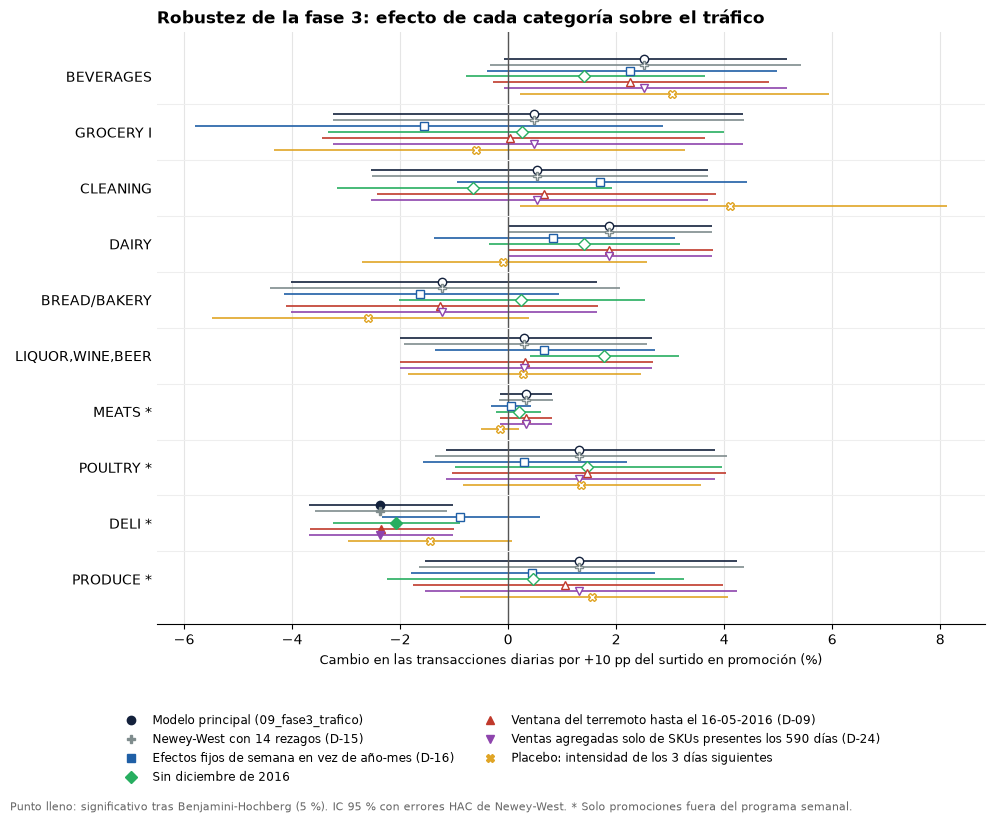

In [10]:
pruebas = [e for e in especificaciones if e != "intensidad_log"]
colores = dict(zip(pruebas, ["#13213c", "#7f8c8d", "#1f5fa6", "#27ae60", "#c0392b", "#8e44ad", "#e0a526"]))
marcadores = dict(zip(pruebas, ["o", "P", "s", "D", "^", "v", "X"]))
desplazamiento = dict(zip(pruebas, np.linspace(0.32, -0.32, len(pruebas))))
etiquetas = {c: f"{c} *" if c in categorias_programa else c for c in categorias}
posiciones = dict(zip(categorias, np.arange(len(categorias))[::-1]))
t = coeficientes.loc[(coeficientes["ecuacion"] == "trafico") & ~coeficientes["es_adelanto"]]

fig, eje = plt.subplots(figsize=(10, 8))
for especificacion in pruebas:
    for fila in t.loc[t["especificacion"] == especificacion].itertuples():
        y = posiciones[fila.categoria_en_promocion_k] + desplazamiento[especificacion]
        color = colores[especificacion]
        eje.hlines(y, fila.efecto_ic_inf_pct, fila.efecto_ic_sup_pct, color=color, linewidth=1.2)
        eje.plot(fila.efecto_pct, y, marcadores[especificacion], color=color, markersize=6,
                 markerfacecolor=color if fila.significativo else "white", zorder=3)
eje.axvline(0, color="#555555", linewidth=1)
eje.set_yticks(list(posiciones.values()), [etiquetas[c] for c in posiciones], fontsize=10)
for y in np.arange(len(categorias) - 1) + 0.5:
    eje.axhline(y, color="#eeeeee", linewidth=0.8)
eje.set_xlabel("Cambio en las transacciones diarias por +10 pp del surtido en promoción (%)", fontsize=9.5)
eje.grid(axis="x", color="#e5e5e5")
eje.set_axisbelow(True)
eje.spines[["top", "right", "left"]].set_visible(False)
eje.tick_params(axis="y", length=0)
eje.set_title("Robustez de la fase 3: efecto de cada categoría sobre el tráfico", loc="left", fontsize=12.5, fontweight="bold")
leyenda = [plt.Line2D([], [], marker=marcadores[e], color=colores[e], linestyle="", label=especificaciones[e]) for e in pruebas]
fig.legend(handles=leyenda, loc="lower center", ncol=2, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.text(0.01, -0.02, "Punto lleno: significativo tras Benjamini-Hochberg (5 %). IC 95 % con errores HAC de Newey-West. "
         "* Solo promociones fuera del programa semanal.", fontsize=8, color="#666666")
fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig(os.path.join(ruta_figuras, f"{prefijo}_trafico.png"), dpi=300, bbox_inches="tight")
plt.show()

## Paso 9. Exportación

In [11]:
salidas = {"coeficientes": coeficientes, "consistencia": consistencia, "resumen": resumen, "cambios": cambios,
           "placebo": placebo, "bh10": bh, "muestras": muestras}
for nombre, tabla in salidas.items():
    tabla.to_csv(os.path.join(ruta_tablas, f"{prefijo}_{nombre}.csv"), index=False)
    print(f"Guardado: {os.path.join(ruta_tablas, f'{prefijo}_{nombre}.csv')}")
print(f"Guardado: {os.path.join(ruta_figuras, f'{prefijo}_trafico.png')}")

Guardado: resultados\tablas\robustez_fase3_coeficientes.csv
Guardado: resultados\tablas\robustez_fase3_consistencia.csv
Guardado: resultados\tablas\robustez_fase3_resumen.csv
Guardado: resultados\tablas\robustez_fase3_cambios.csv
Guardado: resultados\tablas\robustez_fase3_placebo.csv
Guardado: resultados\tablas\robustez_fase3_bh10.csv
Guardado: resultados\tablas\robustez_fase3_muestras.csv
Guardado: resultados\figuras\robustez_fase3_trafico.png


## Paso 10. Lectura automática para la tesis

Frases generadas desde las tablas: ninguna cifra está escrita a mano.

In [12]:
nombres_ecuacion = {"trafico": "Tráfico (10 categorías)", "total": "Efecto total cruzado (90 pares)",
                    "canasta": "Efecto canasta cruzado (90 pares)"}
print("RESUMEN DE ROBUSTEZ DE LA FASE 3\n")
for ecuacion, nombre in nombres_ecuacion.items():
    r = resumen.loc[(resumen["ecuacion"] == ecuacion) & (resumen["especificacion"] != "placebo_adelanto")]
    print(f"{nombre}: {int(r['significativos_principal'].iloc[0])} significativos en el principal.")
    for fila in r.itertuples():
        extra = "" if np.isnan(fila.mediana_abs_diferencia_pp) else f"; cambio típico {fila.mediana_abs_diferencia_pp:.2f} pp"
        print(f"  - {especificaciones[fila.especificacion]}: {int(fila.significativos)} significativos; misma clasificación en "
              f"{fila.pct_misma_conclusion:.0f} %; mismo signo en {fila.pct_mismo_signo:.0f} %{extra}.")

# Resultados destacados del principal y si se mantienen
destacados = principal.loc[principal["significativo"]].reset_index()
if len(destacados):
    print("\nResultados significativos del principal y en cuántas pruebas mantienen su clasificación:")
    for fila in destacados.itertuples():
        c = consistencia.loc[(consistencia["ecuacion"] == fila.ecuacion) & (consistencia["categoria_afectada_j"] == fila.categoria_afectada_j)
                             & (consistencia["categoria_en_promocion_k"] == fila.categoria_en_promocion_k)
                             & (consistencia["especificacion"] != "placebo_adelanto")]
        donde = "" if fila.ecuacion == "trafico" else f" sobre {fila.categoria_afectada_j}"
        print(f"  - {fila.categoria_en_promocion_k}{donde} ({fila.ecuacion}, {fila.clasificacion}, {fila.efecto_pct:+.2f} %): "
              f"se mantiene en {int(c['misma_conclusion'].sum())} de {len(c)} pruebas.")

for ecuacion in ["trafico", "total"]:
    p = placebo.loc[placebo["ecuacion"] == ecuacion]
    print(f"\nPlacebo ({ecuacion}): {int(p['significativo'].sum())} de {len(p)} adelantos significativos tras la corrección.", end="")
print()
for ecuacion in ["trafico", "total", "canasta"]:
    b = bh.loc[bh["ecuacion"] == ecuacion]
    print(f"Benjamini-Hochberg al 10 % ({ecuacion}): {int(b['significativo_5'].sum())} -> {int(b['significativo_10'].sum())} significativos.")
print("\n>>>> Proceso finalizado <<<<")

RESUMEN DE ROBUSTEZ DE LA FASE 3

Tráfico (10 categorías): 1 significativos en el principal.
  - Newey-West con 14 rezagos (D-15): 1 significativos; misma clasificación en 100 %; mismo signo en 100 %; cambio típico 0.00 pp.
  - Efectos fijos de semana en vez de año-mes (D-16): 0 significativos; misma clasificación en 90 %; mismo signo en 90 %; cambio típico 0.94 pp.
  - Sin diciembre de 2016: 1 significativos; misma clasificación en 100 %; mismo signo en 80 %; cambio típico 0.65 pp.
  - Ventana del terremoto hasta el 16-05-2016 (D-09): 1 significativos; misma clasificación en 100 %; mismo signo en 100 %; cambio típico 0.09 pp.
  - Intensidad como log(1+N) (D-07): 2 significativos; misma clasificación en 90 %; mismo signo en 90 %.
  - Ventas agregadas solo de SKUs presentes los 590 días (D-24): 1 significativos; misma clasificación en 100 %; mismo signo en 100 %; cambio típico 0.00 pp.
Efecto total cruzado (90 pares): 4 significativos en el principal.
  - Newey-West con 14 rezagos (D-15

## Paso 11. Cómo reportar estos resultados en la tesis

**Dónde va.** En la sección "Análisis de robustez", después de las fases 1 y 2: la figura `robustez_fase3_trafico.png`, la tabla resumen y el placebo.

**Estructura sugerida** (completar con el Paso 10):

1. **Qué se hizo.** "Se reestimaron las 21 ecuaciones de la fase 3 cambiando, una a la vez, siete decisiones previstas en la metodología [lista], manteniendo en cada caso una matriz de diseño común para que la descomposición tráfico‑canasta siga siendo exacta."
2. **Tráfico.** Si alguna categoría aparece como gancho de tráfico en alguna prueba, y si el efecto negativo de DELI se mantiene.
3. **Descomposición.** Cuántos efectos totales y de canasta son significativos en cada prueba, y si los del principal se mantienen.
4. **Placebo y corrección al 10 %.**
5. **Conclusión.** Qué resultados son robustos y cuáles dependen de una decisión concreta.

**Cuidados:** $\phi_k$ es un efecto sobre **toda la tienda**; en MEATS, POULTRY, DELI y PRODUCE se habla de promociones fuera del programa; un efecto no significativo es falta de información, no ausencia de efecto; la prueba `hac_14` responde parcialmente a la advertencia del hueco del terremoto en la serie (errores HAC); actualizar la limitación "Sin análisis de robustez" de `metodologia.tex`.

*Escriban aquí su interpretación.*